In [237]:
import pandas as pd
df_1 = pd.read_csv('train.csv')
df = df_1.copy()
df.head()

,id,Name,Gender,Age,City,Working Professional or Student,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,0,Aaradhya,Female,49.0,Ludhiana,Working Professional,Chef,NaN,5.0,NaN,NaN,2.0,More than 8 hours,Healthy,BHM,No,1.0,2.0,No,0
1,1,Vivan,Male,26.0,Varanasi,Working Professional,Teacher,NaN,4.0,NaN,NaN,3.0,Less than 5 hours,Unhealthy,LLB,Yes,7.0,3.0,No,1
2,2,Yuvraj,Male,33.0,Visakhapatnam,Student,NaN,5.0,NaN,8.97,2.0,NaN,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
3,3,Yuvraj,Male,22.0,Mumbai,Working Professional,Teacher,NaN,5.0,NaN,NaN,1.0,Less than 5 hours,Moderate,BBA,Yes,10.0,1.0,Yes,1
4,4,Rhea,Female,30.0,Kanpur,Working Professional,Business Analyst,NaN,1.0,NaN,NaN,1.0,5-6 hours,Unhealthy,BBA,Yes,9.0,4.0,Yes,0


In [238]:
missing_df = pd.DataFrame({
    'Columns': df.columns,
    'Missing_Counts': df.isnull().sum().values,
    'Missing_Percentage': ((df.isnull().sum() / len(df) * 100))
})
missing_df = missing_df[missing_df['Missing_Counts']>0].sort_values(by='Missing_Counts', ascending=False).reset_index(drop=True)
missing_df

,Columns,Missing_Counts,Missing_Percentage
0,Academic Pressure,112803,80.172708
1,Study Satisfaction,112803,80.172708
2,CGPA,112802,80.171997
3,Profession,36630,26.034115
4,Work Pressure,27918,19.842217
5,Job Satisfaction,27910,19.836532
6,Dietary Habits,4,0.002843
7,Financial Stress,4,0.002843
8,Degree,2,0.001421


In [239]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 140700 entries, 0 to 140699
Data columns (total 20 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   id                                     140700 non-null  int64  
 1   Name                                   140700 non-null  str    
 2   Gender                                 140700 non-null  str    
 3   Age                                    140700 non-null  float64
 4   City                                   140700 non-null  str    
 5   Working Professional or Student        140700 non-null  str    
 6   Profession                             104070 non-null  str    
 7   Academic Pressure                      27897 non-null   float64
 8   Work Pressure                          112782 non-null  float64
 9   CGPA                                   27898 non-null   float64
 10  Study Satisfaction                     27897 non-null   float64
 11

In [240]:
df = df.drop(['id', 'Name', 'City', 'Degree'], axis=1)

num_cols = ['Age', 'Work/Study Hours', 'Financial Stress', 'Academic Pressure', 
            'Study Satisfaction', 'CGPA', 'Work Pressure', 'Job Satisfaction']
cat_cols = ['Gender', 'Working Professional or Student', 'Profession', 'Sleep Duration', 'Dietary Habits',
            'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']

print(len(num_cols) + len(cat_cols))

15


In [241]:
df[num_cols].skew().round(4)

Age                  -0.2180
Work/Study Hours     -0.1282
Financial Stress      0.0356
Academic Pressure    -0.1340
Study Satisfaction    0.0118
CGPA                 -0.0736
Work Pressure         0.0185
Job Satisfaction      0.0544
dtype: float64

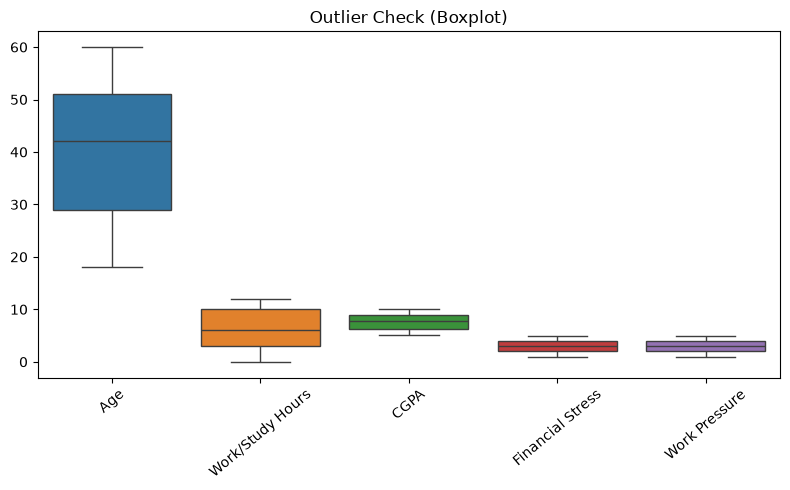

In [242]:
import matplotlib.pyplot as plt
import seaborn as sns

# OUTLIER BOXPLOT & CORRELATION HEATMAP


# Boxplot for Outlier Check
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[['Age', 'Work/Study Hours', 'CGPA', 'Financial Stress', 'Work Pressure']])
plt.title("Outlier Check (Boxplot)")
plt.tick_params(axis='x', rotation=40)

plt.tight_layout()
plt.show()

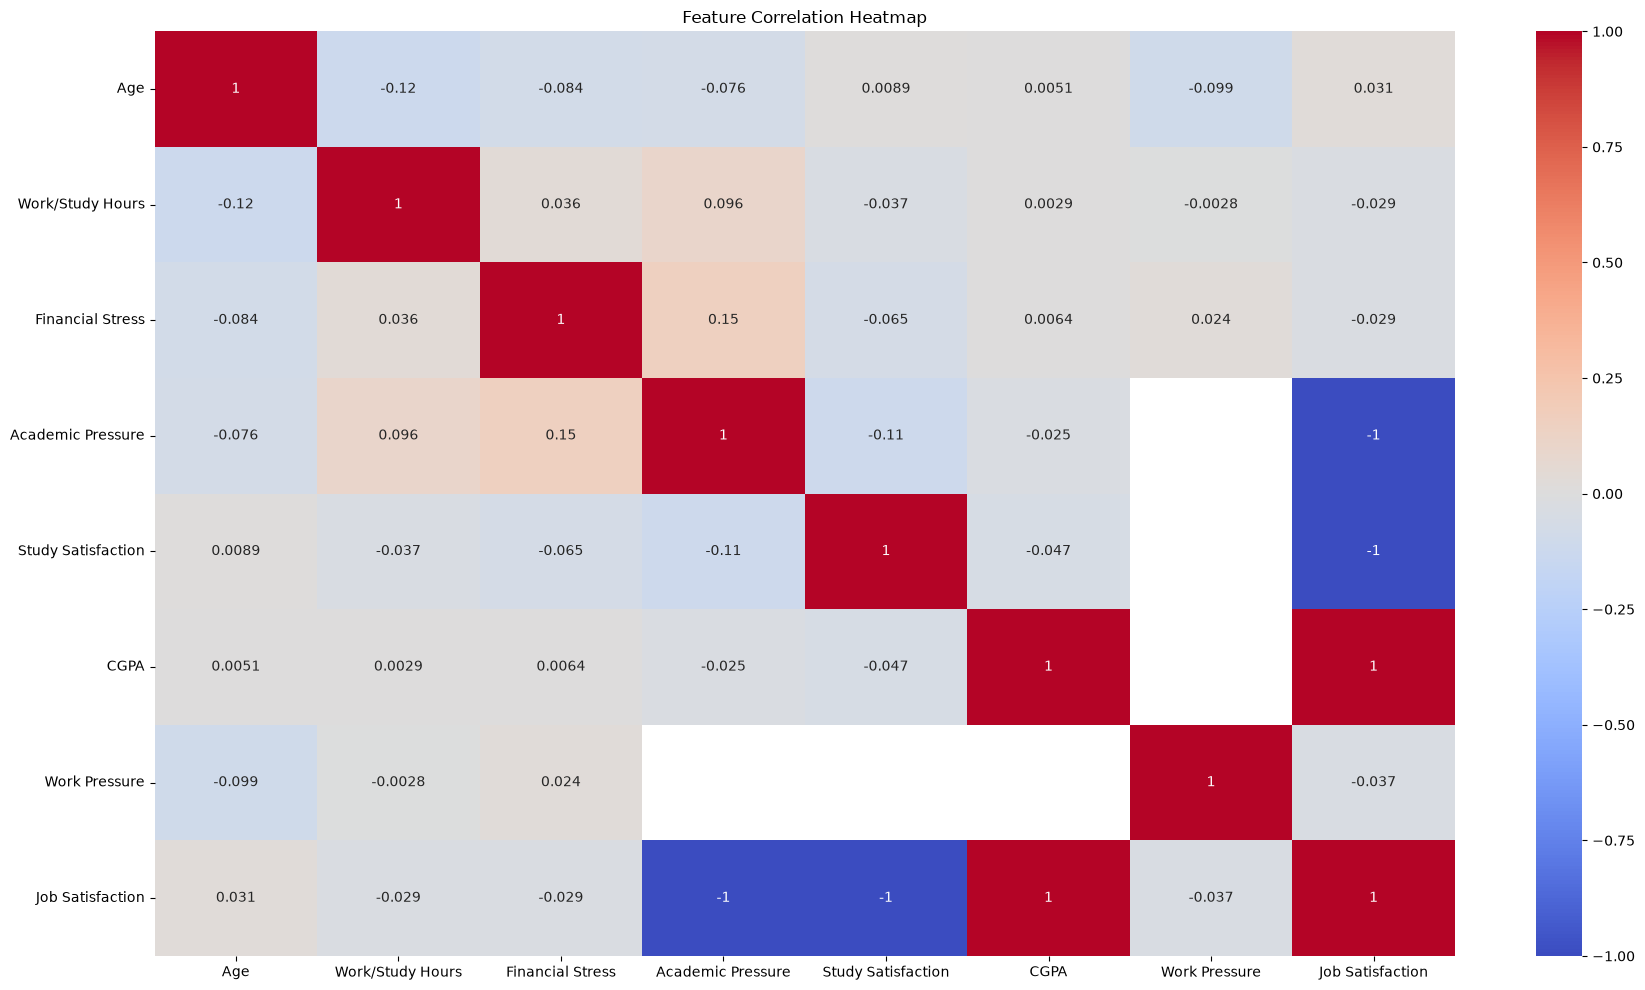

In [243]:
# Correlation Heatmap

plt.figure(figsize=(18, 10))

corr_cols = num_cols
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

In [244]:
df['Academic Pressure'].value_counts()

Academic Pressure
3.0    7463
5.0    6296
4.0    5158
1.0    4801
2.0    4179
Name: count, dtype: int64

In [245]:
status_check = df.groupby('Working Professional or Student')[['Academic Pressure', 'Study Satisfaction', 'CGPA',
                                                             'Work Pressure', 'Job Satisfaction', 'Profession']].count().reset_index()
status_check

,Working Professional or Student,Academic Pressure,Study Satisfaction,CGPA,Work Pressure,Job Satisfaction,Profession
0,Student,27892,27891,27892,3,8,34
1,Working Professional,5,6,6,112779,112782,104036


In [246]:
df['Dietary Habits'].value_counts()

Dietary Habits
Moderate             49705
Unhealthy            46227
Healthy              44741
Yes                      2
More Healthy             2
No                       2
Pratham                  1
BSc                      1
Gender                   1
3                        1
Less than Healthy        1
Mihir                    1
1.0                      1
Hormonal                 1
Electrician              1
No Healthy               1
Less Healthy             1
M.Tech                   1
Vegas                    1
Male                     1
Indoor                   1
Class 12                 1
2                        1
Name: count, dtype: int64

In [247]:
val_values = ['Moderate', 'Unhealthy', 'Healthy']
df ['Dietary Habits'] = df['Dietary Habits'].apply(lambda x: x if x in val_values else 'Moderate')
df['Dietary Habits'].isnull().sum()

np.int64(0)

In [248]:
dietary_habits = {
    'Unhealthy': 0,
    'Moderate' : 1,
    'Healthy': 2
}
df['Dietary Habits'] = df['Dietary Habits'].map(dietary_habits)
df['Dietary Habits'].value_counts()

Dietary Habits
1    49732
0    46227
2    44741
Name: count, dtype: int64

In [249]:
df['Financial Stress'].value_counts()

Financial Stress
2.0    31451
5.0    28279
4.0    27765
1.0    27211
3.0    25990
Name: count, dtype: int64

In [250]:
df['Financial Stress'].describe()

count    140696.000000
mean          2.988983
std           1.413633
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max           5.000000
Name: Financial Stress, dtype: float64

In [251]:
df['Financial Stress'] = df['Financial Stress'].fillna(df['Financial Stress'].median())
df['Financial Stress'].isnull().sum()

np.int64(0)

In [252]:
df[['Academic Pressure', 'Study Satisfaction', 'CGPA','Work Pressure', 'Job Satisfaction']].head()

,Academic Pressure,Study Satisfaction,CGPA,Work Pressure,Job Satisfaction
0,NaN,NaN,NaN,5.0,2.0
1,NaN,NaN,NaN,4.0,3.0
2,5.0,2.0,8.97,NaN,NaN
3,NaN,NaN,NaN,5.0,1.0
4,NaN,NaN,NaN,1.0,1.0


In [253]:
zero_cols = ['Academic Pressure', 'Study Satisfaction', 'CGPA','Work Pressure', 'Job Satisfaction']
for i in zero_cols:
    df[i] = df[i].fillna(0.0)

In [254]:
df[['Academic Pressure', 'Study Satisfaction', 'CGPA','Work Pressure', 'Job Satisfaction']].head()

,Academic Pressure,Study Satisfaction,CGPA,Work Pressure,Job Satisfaction
0,0.0,0.0,0.00,5.0,2.0
1,0.0,0.0,0.00,4.0,3.0
2,5.0,2.0,8.97,0.0,0.0
3,0.0,0.0,0.00,5.0,1.0
4,0.0,0.0,0.00,1.0,1.0


In [255]:
pd.set_option('display.max_rows', None)
df['Profession'].value_counts()

Profession
Teacher                   24906
Content Writer             7814
Architect                  4370
Consultant                 4229
HR Manager                 4022
Pharmacist                 3893
Doctor                     3255
Business Analyst           3161
Entrepreneur               2968
Chemist                    2967
Chef                       2862
Educational Consultant     2852
Data Scientist             2390
Researcher                 2328
Lawyer                     2212
Customer Support           2055
Marketing Manager          1976
Pilot                      1913
Travel Consultant          1860
Plumber                    1748
Sales Executive            1739
Manager                    1737
Judge                      1712
Electrician                1582
Financial Analyst          1574
Software Engineer          1510
Civil Engineer             1470
UX/UI Designer             1452
Digital Marketer           1372
Accountant                 1339
Finanancial Analyst        13

In [256]:
pd.reset_option('display.max_rows')

In [257]:
df.isnull().sum()

Gender                                       0
Age                                          0
Working Professional or Student              0
Profession                               36630
Academic Pressure                            0
Work Pressure                                0
CGPA                                         0
Study Satisfaction                           0
Job Satisfaction                             0
Sleep Duration                               0
Dietary Habits                               0
Have you ever had suicidal thoughts ?        0
Work/Study Hours                             0
Financial Stress                             0
Family History of Mental Illness             0
Depression                                   0
dtype: int64

In [258]:
df['Profession'] = df['Profession'].fillna('Unemployed')

df['Profession'] = df['Profession'].replace({'Finanancial Analyst': 'Financial Analyst'})

In [259]:
df['Profession'].value_counts()

Profession
Unemployed        36633
Teacher           24906
Content Writer     7814
Architect          4370
Consultant         4229
                  ...  
M.Ed                  1
Analyst               1
Pranav                1
Visakhapatnam         1
Yuvraj                1
Name: count, Length: 63, dtype: int64

In [260]:
df.isnull().sum()

Gender                                   0
Age                                      0
Working Professional or Student          0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         0
Family History of Mental Illness         0
Depression                               0
dtype: int64

In [261]:
job_count = df['Profession'].value_counts()
rare_jobs = job_count[job_count < 10].index
df['Profession'] = df['Profession'].replace(rare_jobs, 'Unemplyed')

# One Hot Encoding:
df = pd.get_dummies(df, columns=['Profession'], drop_first=True, dtype=int)

In [262]:
df.head()

,Gender,Age,Working Professional or Student,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,...,Profession_Plumber,Profession_Research Analyst,Profession_Researcher,Profession_Sales Executive,Profession_Software Engineer,Profession_Teacher,Profession_Travel Consultant,Profession_UX/UI Designer,Profession_Unemployed,Profession_Unemplyed
0,Female,49.0,Working Professional,0.0,5.0,0.00,0.0,2.0,More than 8 hours,2,...,0,0,0,0,0,0,0,0,0,0
1,Male,26.0,Working Professional,0.0,4.0,0.00,0.0,3.0,Less than 5 hours,0,...,0,0,0,0,0,1,0,0,0,0
2,Male,33.0,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,2,...,0,0,0,0,0,0,0,0,1,0
3,Male,22.0,Working Professional,0.0,5.0,0.00,0.0,1.0,Less than 5 hours,1,...,0,0,0,0,0,1,0,0,0,0
4,Female,30.0,Working Professional,0.0,1.0,0.00,0.0,1.0,5-6 hours,0,...,0,0,0,0,0,0,0,0,0,0


In [263]:
df['Working Professional or Student'].value_counts().reset_index()

,Working Professional or Student,count
0,Working Professional,112799
1,Student,27901


In [264]:
work_stu_map = {
    'Student': 0,
    'Working Professional': 1
}
df['Working Professional or Student'] = df['Working Professional or Student'].map(work_stu_map)
df['Working Professional or Student']

0         1
1         1
2         0
3         1
4         1
         ..
140695    1
140696    1
140697    1
140698    1
140699    0
Name: Working Professional or Student, Length: 140700, dtype: int64

In [265]:
df['Sleep Duration'].value_counts()

Sleep Duration
Less than 5 hours    38784
7-8 hours            36969
More than 8 hours    32726
5-6 hours            32142
3-4 hours               12
6-7 hours                8
4-5 hours                7
4-6 hours                5
2-3 hours                5
6-8 hours                4
1-6 hours                4
No                       4
Sleep_Duration           2
10-11 hours              2
8-9 hours                2
9-11 hours               2
45                       2
Unhealthy                2
1-2 hours                1
40-45 hours              1
Moderate                 1
55-66 hours              1
9-6 hours                1
1-3 hours                1
Indore                   1
35-36 hours              1
8 hours                  1
10-6 hours               1
than 5 hours             1
49 hours                 1
Work_Study_Hours         1
3-6 hours                1
45-48 hours              1
9-5                      1
Pune                     1
9-5 hours                1
Name: count, 

In [266]:
valid_sleep = ['Less than 5 hours', '5-6 hours', '7-8 hours', 'More than 8 hours']
df['Sleep Duration'] = df['Sleep Duration'].apply(lambda x: x if x in valid_sleep else '5-6 hours')
sleep_map = {
    'Less than 5 hours': 0,
    '5-6 hours': 1,
    '7-8 hours': 2,
    'More than 8 hours': 3
}
df['Sleep Duration'] = df['Sleep Duration'].map(sleep_map)
df['Sleep Duration']

0         3
1         0
2         1
3         0
4         1
         ..
140695    1
140696    2
140697    3
140698    1
140699    0
Name: Sleep Duration, Length: 140700, dtype: int64

In [267]:
df.select_dtypes(['object', 'str'])

,Gender,Have you ever had suicidal thoughts ?,Family History of Mental Illness
0,Female,No,No
1,Male,Yes,No
2,Male,Yes,No
3,Male,Yes,Yes
4,Female,Yes,Yes
...,...,...,...
140695,Female,No,Yes
140696,Female,Yes,Yes
140697,Female,No,No
140698,Female,Yes,No


In [268]:
gender_map = {'Female': 0, 'Male': 1}
df['Gender'] = df['Gender'].map(gender_map)

yes_no_map = {'No': 0, 'Yes': 1}
df['Have you ever had suicidal thoughts ?'] = df['Have you ever had suicidal thoughts ?'].map(yes_no_map)
df['Family History of Mental Illness'] = df['Family History of Mental Illness'].map(yes_no_map)

df[['Gender', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']].head()

,Gender,Have you ever had suicidal thoughts ?,Family History of Mental Illness
0,0,0,0
1,1,1,0
2,1,1,0
3,1,1,1
4,0,1,1


In [269]:
import gc
gc.collect()

71148

In [270]:
final_columns = df.select_dtypes(include=['int','float']).columns.to_list()
print(len(final_columns))

50


In [271]:
# Balance Checking:
(df['Depression'].value_counts(normalize=True) * 100).round(2)

Depression
0    81.83
1    18.17
Name: proportion, dtype: float64

In [272]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 140700 entries, 0 to 140699
Data columns (total 50 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   Gender                                 140700 non-null  int64  
 1   Age                                    140700 non-null  float64
 2   Working Professional or Student        140700 non-null  int64  
 3   Academic Pressure                      140700 non-null  float64
 4   Work Pressure                          140700 non-null  float64
 5   CGPA                                   140700 non-null  float64
 6   Study Satisfaction                     140700 non-null  float64
 7   Job Satisfaction                       140700 non-null  float64
 8   Sleep Duration                         140700 non-null  int64  
 9   Dietary Habits                         140700 non-null  int64  
 10  Have you ever had suicidal thoughts ?  140700 non-null  int64  
 11

In [273]:
# Skewness Check (Full Data):
df[num_cols].skew().round(4)

Age                  -0.2180
Work/Study Hours     -0.1282
Financial Stress      0.0356
Academic Pressure     2.1203
Study Satisfaction    2.1918
CGPA                  1.6714
Work Pressure         0.0538
Job Satisfaction      0.0850
dtype: float64

In [274]:
# Skewness Check (Students Only):
students_only = df[df['Working Professional or Student'] == 0]
print(students_only[['Academic Pressure', 'Study Satisfaction', 'CGPA']].skew().round(4))

Academic Pressure    -0.1352
Study Satisfaction    0.0104
CGPA                 -0.1131
dtype: float64


No True Skew! 

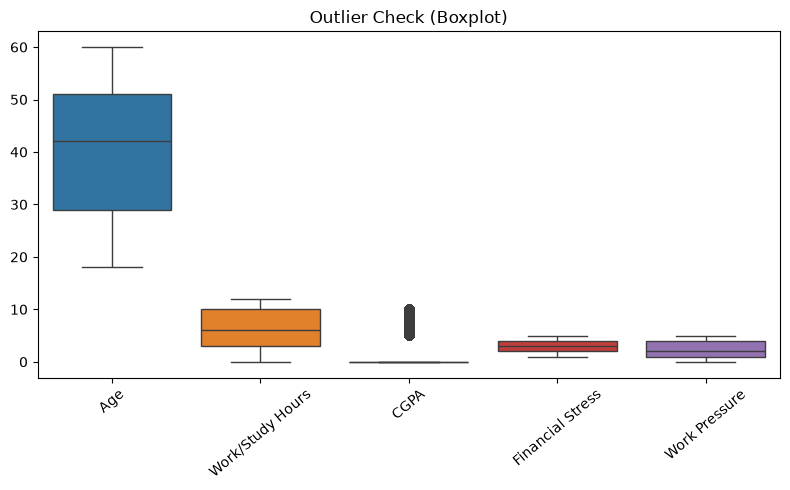

In [275]:

# Boxplot for Outlier Check
plt.figure(figsize=(8, 5))

sns.boxplot(data=df[['Age', 'Work/Study Hours', 'CGPA', 'Financial Stress', 'Work Pressure']])
plt.title("Outlier Check (Boxplot)")
plt.tick_params(axis='x', rotation=40)

plt.tight_layout()
plt.show()

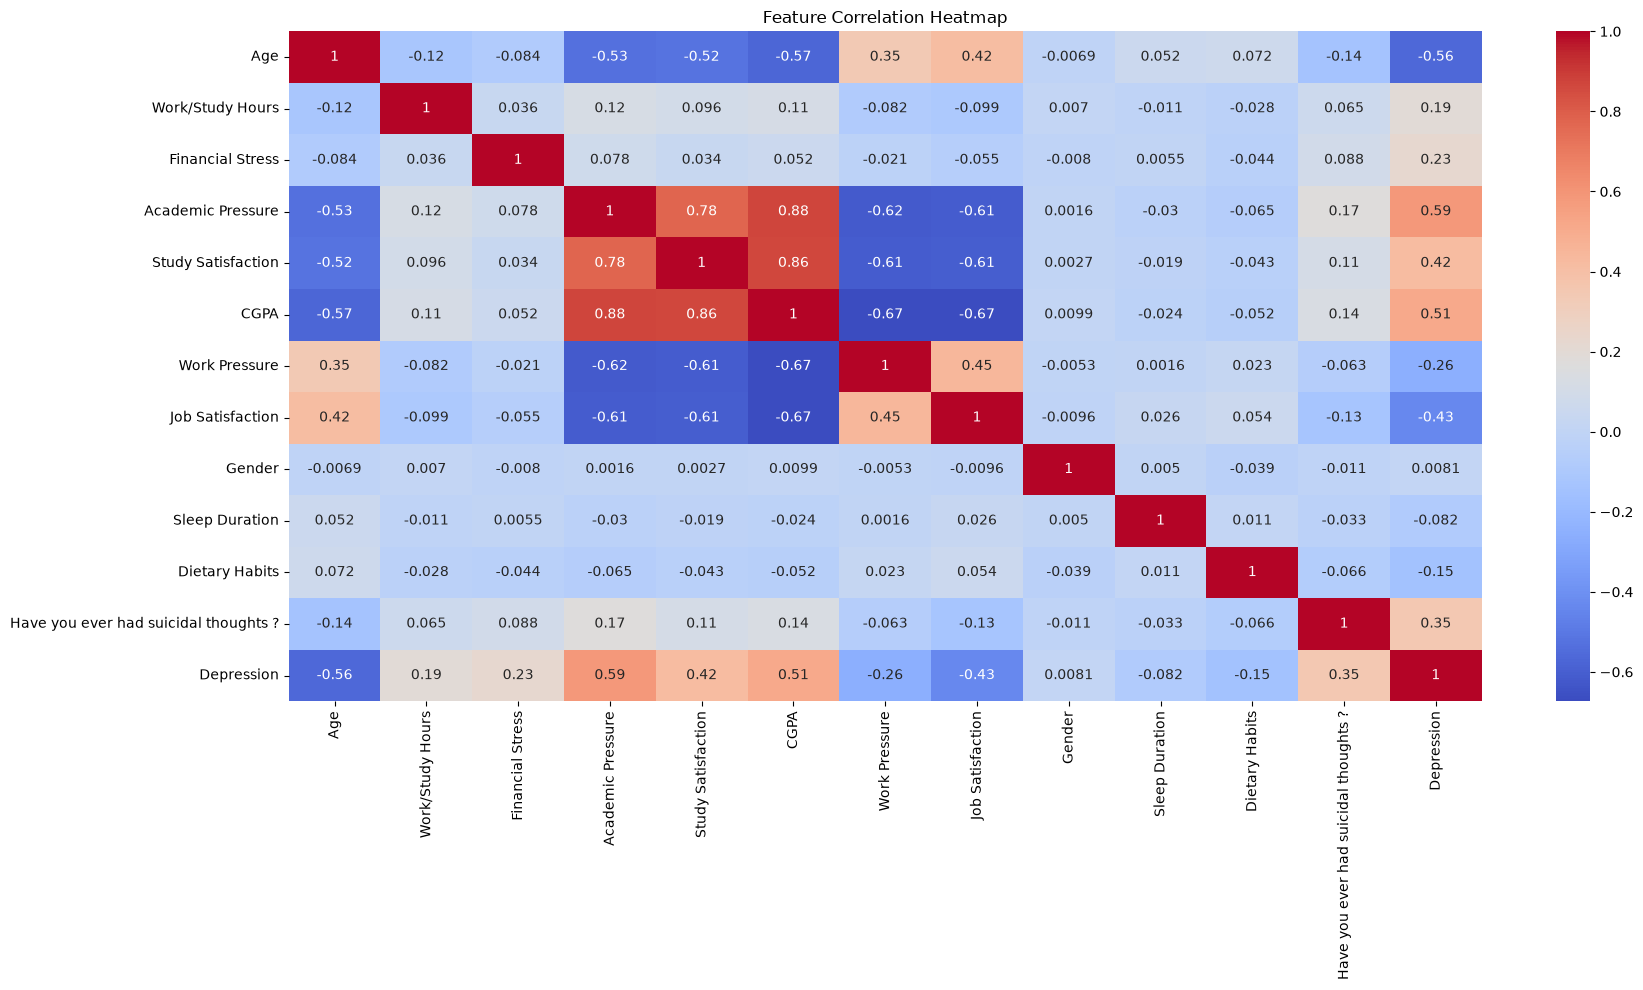

In [276]:
# Correlation Heatmap

plt.figure(figsize=(18, 10))

corr_cols = num_cols + ['Gender', 'Sleep Duration', 'Dietary Habits', 
                        'Have you ever had suicidal thoughts ?', 'Depression']
sns.heatmap(df[corr_cols].corr(), annot=True, cmap='coolwarm')
plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

In [277]:
df.to_csv('final_cleaned_train.csv',index=False)

In [1]:
import gc
gc.collect()

858